# Project 02: Data Visualization with Matplotlib & Seaborn
### InternCircle – Data Science & AI

**Objective:** Create clear and informative visualizations from the Tips dataset using Matplotlib and Seaborn.

**Dataset:** Seaborn Tips Dataset

**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn

This project explores bill amounts, tips, dining days, time of day, and relationships between numerical variables.

## 1. Importing Required Libraries

We import the libraries needed to load, inspect, analyze, and visualize the dataset.

- **Pandas** is used for data handling.
- **NumPy** supports numerical operations.
- **Matplotlib** creates and formats plots.
- **Seaborn** provides statistical visualizations.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading the Tips Dataset

The Tips dataset is loaded using Seaborn. It contains information about restaurant bills, tips, days, meal times, smoking status, and party sizes.

We display the first five rows to understand the dataset.

In [3]:
tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## 3. Understanding the Dataset

We inspect the dataset's dimensions, column names, data types, missing values, and summary statistics before creating visualizations.

In [4]:
print("Dataset shape:", tips.shape)
print("\\nDataset information:")
tips.info()
print("\\nMissing values:")
print(tips.isna().sum())
print("\\nStatistical summary:")
tips.describe()

Dataset shape: (244, 7)
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB
\nMissing values:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64
\nStatistical summary:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


## 4. Questions to Explore

The visualizations will answer these four questions:

1. How are total bills distributed?
2. How do tips vary across different days?
3. Is there a relationship between total bill and tip?
4. Which numerical variables are most strongly correlated?

## 5. Setting the Visualization Style

We use a consistent Seaborn theme and a readable colour palette. Clear titles, axis labels, and units make each chart easier to understand.

In [5]:
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)

## 6. Histogram – Distribution of Total Bills

A histogram shows how frequently bill amounts occur within ranges. It helps us understand the distribution of total restaurant bills.

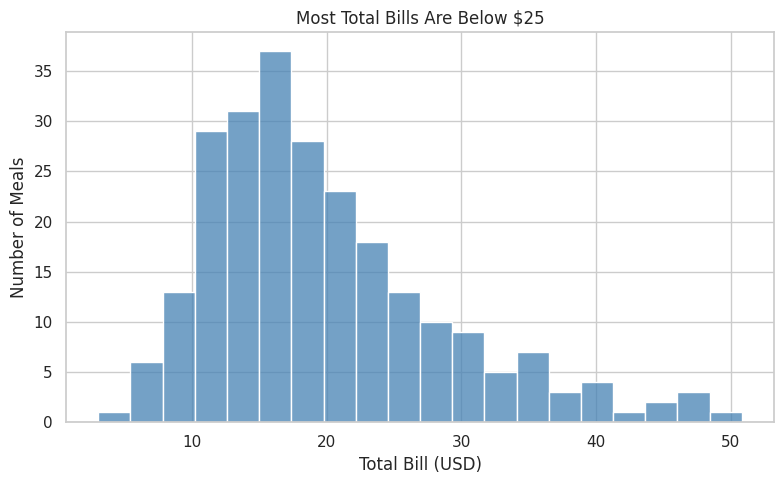

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(data=tips, x="total_bill", bins=20, color="steelblue")
plt.title("Most Total Bills Are Below $25")
plt.xlabel("Total Bill (USD)")
plt.ylabel("Number of Meals")
plt.tight_layout()
plt.show()

**Takeaway:** Most restaurant bills are concentrated below approximately $25, while only a smaller number of meals have higher bills.

## 7. Box Plot – Tips by Day

A box plot compares the distribution of tips across the days of the week. It displays the median, spread, and potential outliers for each day.

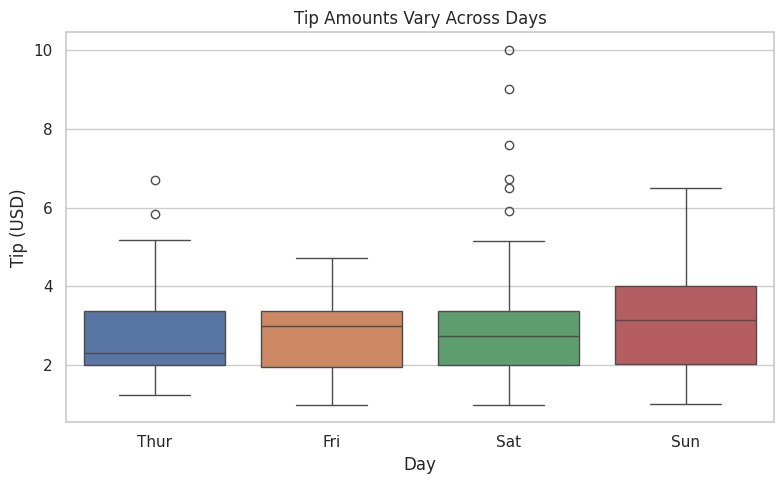

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=tips, x="day", y="tip", hue="day", palette="deep", legend=False)
plt.title("Tip Amounts Vary Across Days")
plt.xlabel("Day")
plt.ylabel("Tip (USD)")
plt.tight_layout()
plt.show()

**Takeaway:** Tip amounts vary by day, and the box plot also shows that some meals receive unusually high tips.

## 8. Scatter Plot – Total Bill vs Tip

A scatter plot helps us examine the relationship between two numerical variables. Colour represents the meal time so that lunch and dinner can be compared.

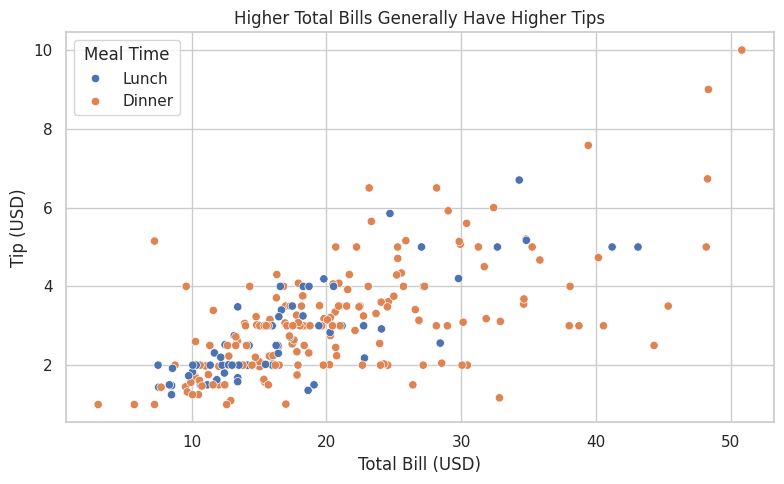

In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", palette="deep")
plt.title("Higher Total Bills Generally Have Higher Tips")
plt.xlabel("Total Bill (USD)")
plt.ylabel("Tip (USD)")
plt.legend(title="Meal Time")
plt.tight_layout()
plt.show()

**Takeaway:** The scatter plot shows a positive relationship: meals with larger total bills generally have larger tips.

## 9. Correlation Heatmap – Relationships Between Numerical Variables

A correlation matrix measures the strength and direction of linear relationships between numerical columns. Values closer to +1 indicate a stronger positive relationship, while values closer to -1 indicate a stronger negative relationship.

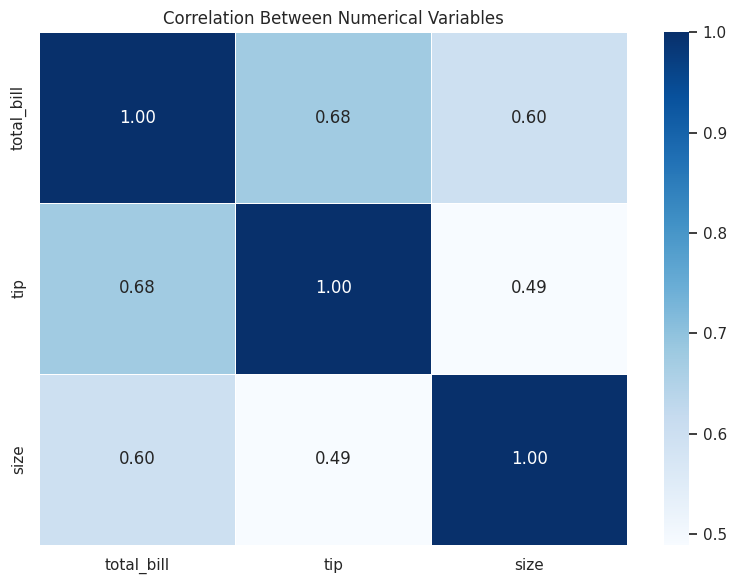

In [9]:
correlation = tips.select_dtypes(include="number").corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="Blues", fmt=".2f", linewidths=0.5)
plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

**Takeaway:** Total bill and tip show the strongest positive relationship among the main spending variables in this dataset.

## 10. Combined Dashboard – Four Visualizations

The four charts are combined into a 2 × 2 dashboard, as required in the project guide. The final image is saved at 150 DPI for clear viewing and submission.

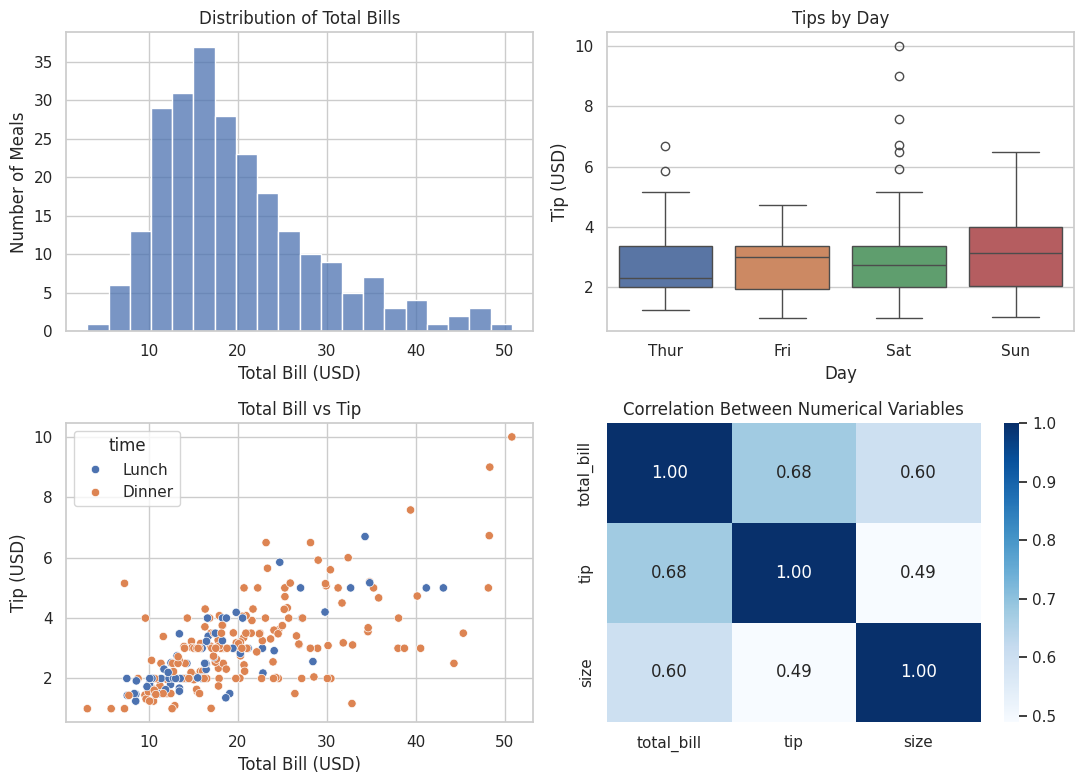

In [10]:
sns.set_theme(style="whitegrid", palette="deep")
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

sns.histplot(data=tips, x="total_bill", bins=20, ax=axes[0, 0])
axes[0, 0].set(title="Distribution of Total Bills", xlabel="Total Bill (USD)", ylabel="Number of Meals")

sns.boxplot(data=tips, x="day", y="tip", hue="day", palette="deep", legend=False, ax=axes[0, 1])
axes[0, 1].set(title="Tips by Day", xlabel="Day", ylabel="Tip (USD)")

sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", palette="deep", ax=axes[1, 0])
axes[1, 0].set(title="Total Bill vs Tip", xlabel="Total Bill (USD)", ylabel="Tip (USD)")

sns.heatmap(tips.select_dtypes(include="number").corr(), annot=True, cmap="Blues", fmt=".2f", ax=axes[1, 1])
axes[1, 1].set_title("Correlation Between Numerical Variables")

plt.tight_layout()
plt.savefig("tips_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Final Findings

1. **Bill Distribution:** Most total bills are below approximately $25.
2. **Tips by Day:** Tip distributions differ across days, with some high-value outliers.
3. **Bill and Tip Relationship:** Larger bills generally tend to be associated with larger tips.
4. **Correlation:** Total bill and tip have a positive relationship in the numerical correlation matrix.

## 12. Conclusion

This project used Matplotlib and Seaborn to explore the Tips dataset through a histogram, box plot, scatter plot, and correlation heatmap. Each visualization was given a clear title and labelled axes. The four charts were also combined into a 2 × 2 dashboard and saved as an image.